# 02. Naive estimates vs g-methods

One simulated dataset, every estimator, compared with the truth.

- **Count regression, all handoffs.** Complaint on handoff counts from the raw
  log. Escalations logged after a complaint inflate the escalation effect.
- **Count regression, "before complaint, or all".** Fixes the reverse causality
  but gives complainers a shorter exposure window than everyone else.
- **Count regression plus sentiment.** Adjusts for frustration, which handoffs
  partly cause.
- **Pooled hazard.** Turn-level model on current covariates. Holds later
  frustration and waits at their observed values, so it misses the effect that
  runs through them.
- **Parametric g-formula.** Models every time-varying variable and simulates
  forward under each intervention.
- **IPW.** Weights by the treatment model only. A cross-check that relies on
  different modelling assumptions.
- **LTMLE.** Sequential outcome regressions, targeted with the IPW weights.
  Doubly robust, with influence-function intervals. The recommended estimator.

In [1]:
import pandas as pd

from gmethods import (
    IPW, LTMLE, ChatSimulator, CountRegression, GFormula, PooledHazard, Scenario,
)
from gmethods import interventions as iv
from gmethods.estimators import natural_course_check, positivity_table, weight_summary

pd.set_option("display.width", 120)

In [2]:
import matplotlib.pyplot as plt

# Reference categorical palette, fixed order. Truth is drawn in ink.
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "legend.frameon": False,
})

In [3]:
sim = ChatSimulator(Scenario.preset("baseline"))
data = sim.simulate(n_chats=50_000, seed=1)
regimes = iv.standard_set()
halving = iv.scale_set()
truth = sim.true_risks(regimes + halving[1:], n_mc=500_000)

In [4]:
fast = {"max_iter": 100, "learning_rate": 0.1}
gf = GFormula(learner_params=fast).fit(data.panel)
ipw = IPW(learner_params=fast).fit(data.panel)
ltmle = LTMLE().fit(data.panel)
tables = {
    "count, all handoffs": CountRegression("all").fit(data.chats).estimate(regimes),
    "count, before complaint or all": CountRegression("before_complaint_or_all")
        .fit(data.chats).estimate(regimes),
    "count + sentiment": CountRegression("before_complaint_or_all", adjust_sentiment=True)
        .fit(data.chats).estimate(regimes),
    "pooled hazard": PooledHazard().fit(data.panel).estimate(regimes),
    "IPW": ipw.estimate(regimes),
    "g-formula": gf.estimate(regimes, n_mc=20_000),
    "LTMLE": ltmle.estimate(regimes),
}
rd = pd.DataFrame({k: t.to_frame()["rd"] for k, t in tables.items()})
rd.insert(0, "truth", truth.to_frame()["rd"].loc[rd.index])
(rd.drop(index="natural_course") * 1000).round(2)

,truth,"count, all handoffs","count, before complaint or all",count + sentiment,pooled hazard,IPW,g-formula,LTMLE
regime,,,,,,,,
never_transfer,-0.44,-1.89,-2.56,-2.60,-1.15,-1.21,-0.40,-0.65
never_escalation,-4.09,-9.11,-3.36,-3.46,-1.30,-4.69,-3.58,-4.27
never_requeue,-3.09,-0.81,-2.27,-2.28,-1.15,-3.19,-2.68,-3.12
never_shift_change,-1.33,-0.24,-0.45,-0.47,-0.45,-1.33,-1.26,-1.32
never_any,-5.69,-10.46,-7.08,-7.18,-3.73,-8.96,-4.46,-6.47


Risk differences per 1,000 chats against the natural course.

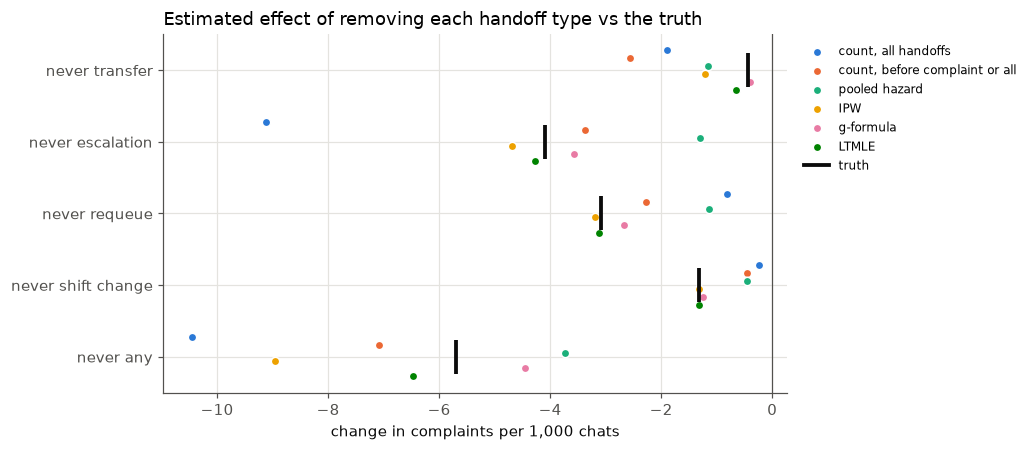

In [5]:
import numpy as np

shown = [r for r in rd.index if r != "natural_course"]
# Six estimators keep the categorical palette within its validated range.
est = ["count, all handoffs", "count, before complaint or all", "pooled hazard",
       "IPW", "g-formula", "LTMLE"]
fig, ax = plt.subplots(figsize=(9.5, 4.2))
y = np.arange(len(shown))
step = 0.11
for j, name in enumerate(est):
    off = (j - (len(est) - 1) / 2) * step
    ax.scatter(rd.loc[shown, name] * 1000, y + off, s=30, color=SERIES[j], label=name,
               edgecolor="white", linewidth=1, zorder=3)
ax.scatter(rd.loc[shown, "truth"] * 1000, y, marker="|", s=500, color=INK, lw=2.5, zorder=4)
ax.set_yticks(y, [s.replace("_", " ") for s in shown])
ax.invert_yaxis()
ax.axvline(0, color=MUTED, lw=0.8)
ax.set_xlabel("change in complaints per 1,000 chats")
ax.set_title("Estimated effect of removing each handoff type vs the truth", loc="left")
handles, labels = ax.get_legend_handles_labels()
handles.append(plt.Line2D([], [], color=INK, lw=2.5))
labels.append("truth")
ax.legend(handles, labels, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()

## LTMLE intervals, and halving instead of removing

"Never transfer" asks about chats that stay with the wrong team, which the
data barely contains. Halving each handoff type needs far weaker positivity.
LTMLE gives a 95% interval for every regime from its influence function.

In [6]:
table = ltmle.estimate(regimes + halving[1:]).to_frame()
table["truth"] = truth.to_frame()["rd"]
(table[["rd", "rd_low", "rd_high", "truth"]].drop(index="natural_course") * 1000).round(2)

,rd,rd_low,rd_high,truth
regime,,,,
never_transfer,-0.65,-3.42,2.11,-0.44
never_escalation,-4.27,-5.13,-3.40,-4.09
never_requeue,-3.12,-3.76,-2.49,-3.09
never_shift_change,-1.32,-1.90,-0.75,-1.33
never_any,-6.47,-8.39,-4.55,-5.69
scale_transfer_0.5,0.04,-0.65,0.73,-0.11
scale_escalation_0.5,-1.94,-2.34,-1.53,-1.89
scale_requeue_0.5,-1.61,-1.94,-1.29,-1.66
scale_shift_change_0.5,-0.48,-1.06,0.09,-0.30


## Diagnostics

The g-formula's natural course should reproduce the observed data: the
cumulative complaint risk and the mean of each confounder by turn.

In [7]:
natural_course_check(gf, n_turns=8).round(3)

,risk_obs,risk_sim,queue_length_obs,queue_length_sim,wait_obs,wait_sim,shift_time_left_obs,shift_time_left_sim,skill_mismatch_obs,skill_mismatch_sim,with_specialist_obs,with_specialist_sim,sentiment_obs,sentiment_sim,idle_obs,idle_sim
turn,,,,,,,,,,,,,,,,
1,0.001,0.001,12.341,12.308,1.288,1.283,152.091,151.565,0.187,0.186,0.000,0.000,0.632,0.629,1.732,1.707
2,0.002,0.002,12.340,12.300,1.848,1.874,148.094,146.307,0.125,0.125,0.008,0.008,1.183,1.191,2.016,2.010
3,0.005,0.004,12.339,12.335,1.852,1.867,144.855,142.715,0.085,0.084,0.021,0.023,1.588,1.590,2.253,2.259
4,0.007,0.006,12.346,12.315,1.884,1.828,142.331,140.707,0.060,0.058,0.038,0.038,1.885,1.882,2.445,2.448
5,0.009,0.008,12.354,12.328,1.827,1.811,139.631,138.971,0.054,0.051,0.059,0.057,2.082,2.091,2.578,2.617
6,0.011,0.010,12.348,12.307,1.854,1.804,137.807,137.271,0.050,0.049,0.082,0.078,2.230,2.236,2.703,2.688
7,0.013,0.012,12.328,12.320,1.921,1.887,136.487,136.154,0.049,0.048,0.106,0.103,2.346,2.350,2.762,2.819
8,0.015,0.014,12.327,12.287,1.952,1.923,135.275,136.018,0.048,0.050,0.132,0.130,2.441,2.448,2.875,2.926


Positivity: removal regimes need "no handoff" to be possible at every turn.
IPW weights show where it is thin. Transfers are close to certain for misrouted
chats, which is why IPW struggles with `never_transfer`.

In [8]:
weight_summary(ipw).round(3)

,mean,max,share_censored,ess
natural_course,1.000,1.000,0.000,335900.000
never_transfer,1.030,131.009,0.210,99979.494
never_escalation,0.979,31.333,0.089,296214.336
never_requeue,0.983,6.280,0.060,313258.401
never_shift_change,0.949,253.065,0.066,210273.720
never_any,0.946,274.032,0.338,53630.664


In [9]:
positivity_table(ipw, by="skill_mismatch").round(3)

,turns,mean_p_transfer,share_p_transfer_lt_0.01,mean_p_escalation,share_p_escalation_lt_0.01,mean_p_requeue,share_p_requeue_lt_0.01,mean_p_shift_change,share_p_shift_change_lt_0.01,share_p_none_lt_0.01
skill_mismatch,,,,,,,,,,
0,305949,0.010,0.599,0.018,0.541,0.012,0.739,0.014,0.965,0.0
1,29951,0.268,0.002,0.020,0.498,0.008,0.818,0.011,0.969,0.0
